In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")

df = pd.read_csv('Global_Superstore(CSV).csv')

df.columns = df.columns.str.strip()

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

print("Retail dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Retail dataset loaded successfully!
Dataset shape: (1000, 24)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Postal Code', 'City', 'State', 'Country', 'Region', 'Market', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Cost', 'Order Priority']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Postal Code,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,40098,CA-2014-AB10015140-41954,2014-11-11,11/13/2014,First Class,AB-100151402,Aaron Bergman,Consumer,73120.0,Oklahoma City,...,TEC-PH-5816,Technology,Phones,Samsung Convoy 3,221.98,2,0.0,62.15,40.77,High
1,26341,IN-2014-JR162107-41675,2014-02-05,2/7/2014,Second Class,JR-162107,Justin Ritter,Corporate,NaN,Wollongong,...,FUR-CH-5379,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.40,9,0.1,-288.77,923.63,Critical
2,25330,IN-2014-CR127307-41929,2014-10-17,10/18/2014,First Class,CR-127307,Craig Reiter,Consumer,NaN,Brisbane,...,TEC-PH-5356,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.17,9,0.1,919.97,915.49,Medium
3,13524,ES-2014-KM1637548-41667,2014-01-28,1/30/2014,First Class,KM-1637548,Katherine Murray,Home Office,NaN,Berlin,...,TEC-PH-5267,Technology,Phones,"Motorola Smart Phone, Cordless",2892.51,5,0.1,-96.54,910.16,Medium
4,47221,SG-2014-RH9495111-41948,2014-11-05,11/6/2014,Same Day,RH-9495111,Rick Hansen,Consumer,NaN,Dakar,...,TEC-CO-6011,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.96,8,0.0,311.52,903.04,Critical


In [4]:
print("Dataset information:")
df.info()
print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))
print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()
df = df.dropna(subset=["Order Date", "Sales", "Profit", "Quantity", "Category"]).copy()

for col in ["Sales", "Profit", "Quantity", "Discount"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Sales", "Profit", "Quantity", "Discount"]).copy()

df = df[(df["Quantity"] > 0) &(df["Sales"] >= 0)].copy()
print("\nCleaned dataset shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

display(df.head())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          1000 non-null   int64         
 1   Order ID        1000 non-null   object        
 2   Order Date      1000 non-null   datetime64[ns]
 3   Ship Date       1000 non-null   object        
 4   Ship Mode       1000 non-null   object        
 5   Customer ID     1000 non-null   object        
 6   Customer Name   1000 non-null   object        
 7   Segment         1000 non-null   object        
 8   Postal Code     194 non-null    float64       
 9   City            1000 non-null   object        
 10  State           1000 non-null   object        
 11  Country         1000 non-null   object        
 12  Region          1000 non-null   object        
 13  Market          1000 non-null   object        
 14  Product ID      1000 non-null   obje

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Postal Code,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,40098,CA-2014-AB10015140-41954,2014-11-11,11/13/2014,First Class,AB-100151402,Aaron Bergman,Consumer,73120.0,Oklahoma City,...,TEC-PH-5816,Technology,Phones,Samsung Convoy 3,221.98,2,0.0,62.15,40.77,High
1,26341,IN-2014-JR162107-41675,2014-02-05,2/7/2014,Second Class,JR-162107,Justin Ritter,Corporate,NaN,Wollongong,...,FUR-CH-5379,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.40,9,0.1,-288.77,923.63,Critical
2,25330,IN-2014-CR127307-41929,2014-10-17,10/18/2014,First Class,CR-127307,Craig Reiter,Consumer,NaN,Brisbane,...,TEC-PH-5356,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.17,9,0.1,919.97,915.49,Medium
3,13524,ES-2014-KM1637548-41667,2014-01-28,1/30/2014,First Class,KM-1637548,Katherine Murray,Home Office,NaN,Berlin,...,TEC-PH-5267,Technology,Phones,"Motorola Smart Phone, Cordless",2892.51,5,0.1,-96.54,910.16,Medium
4,47221,SG-2014-RH9495111-41948,2014-11-05,11/6/2014,Same Day,RH-9495111,Rick Hansen,Consumer,NaN,Dakar,...,TEC-CO-6011,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.96,8,0.0,311.52,903.04,Critical


In [5]:
print("Numerical summary:")
display(df[["Sales", "Quantity", "Discount", "Profit"]].describe().round(2))
print("\nTotal sales:", round(df["Sales"].sum(), 2))
print("Total profit:", round(df["Profit"].sum(), 2))
print("Total quantity sold:", int(df["Quantity"].sum()))
print("\nAverage order-line sales:", round(df["Sales"].mean(), 2))
print("Average profit per order line:", round(df["Profit"].mean(), 2))

Numerical summary:


,Sales,Quantity,Discount,Profit
count,1000.00,1000.00,1000.00,1000.00
mean,1710.97,5.56,0.09,288.92
std,1259.24,2.72,0.15,574.50
min,1.91,1.00,0.00,-3059.82
25%,826.91,4.00,0.00,10.04
50%,1585.12,5.00,0.00,190.68
75%,2477.81,7.00,0.15,518.87
max,9892.74,14.00,0.80,4946.37



Total sales: 1710971.47
Total profit: 288920.44
Total quantity sold: 5558

Average order-line sales: 1710.97
Average profit per order line: 288.92


,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Technology,756983.02,145068.68,2321
Furniture,601492.31,82188.95,1782
Office Supplies,352496.14,61662.81,1455


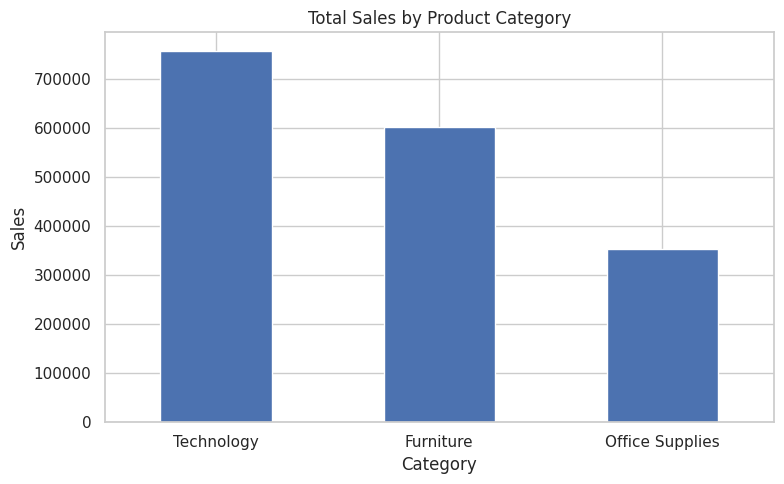

In [6]:
category_summary = df.groupby("Category").agg(Total_Sales=("Sales", "sum"),Total_Profit=("Profit", "sum"),Total_Quantity=("Quantity", "sum")).sort_values("Total_Sales", ascending=False)
display(category_summary.round(2))
category_summary["Total_Sales"].plot(kind="bar",figsize=(8, 5),title="Total Sales by Product Category",ylabel="Sales",xlabel="Category",rot=0)
plt.tight_layout()
plt.show()

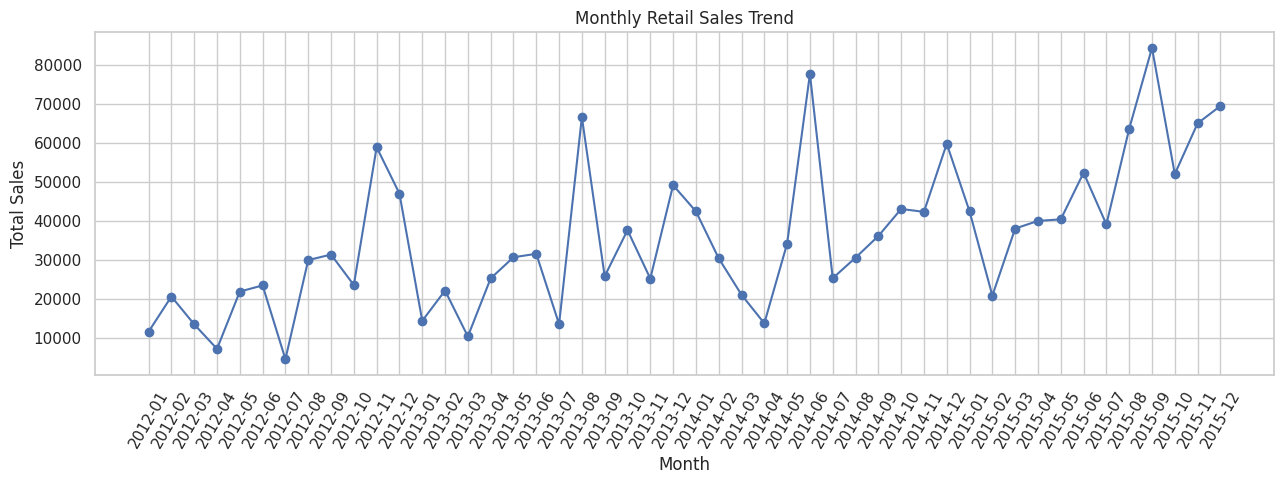

Month with highest sales: 2015-09
Highest monthly sales: 84348.76


In [7]:
df["Order Month"] = df["Order Date"].dt.to_period("M")
monthly_sales = (df.groupby("Order Month")["Sales"].sum().sort_index())
monthly_sales.index = monthly_sales.index.astype(str)
plt.figure(figsize=(13, 5))
plt.plot(monthly_sales.index,monthly_sales.values,marker="o")
plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()
print("Month with highest sales:", monthly_sales.idxmax())
print("Highest monthly sales:", round(monthly_sales.max(), 2))

In [8]:
product_summary = df.groupby("Product Name").agg(Total_Sales=("Sales", "sum"),Total_Profit=("Profit", "sum"),Quantity_Sold=("Quantity", "sum"))
print("Top 10 products by sales:")
display(product_summary.sort_values("Total_Sales", ascending=False).head(10).round(2))
print("10 least profitable products:")
display(product_summary.sort_values("Total_Profit", ascending=True).head(10).round(2))

Top 10 products by sales:


,Total_Sales,Total_Profit,Quantity_Sold
Product Name,,,
"Motorola Smart Phone, Full Size",48542.52,13088.28,84
"Apple Smart Phone, Full Size",42303.44,2651.09,84
"Cisco Smart Phone, Full Size",41325.20,9662.99,76
"Nokia Smart Phone, Full Size",27661.97,5765.12,52
"Samsung Smart Phone, Cordless",25438.59,920.16,55
"Hoover Stove, Red",23477.81,10288.61,45
"Motorola Smart Phone, with Caller ID",23239.44,4395.75,38
"Harbour Creations Executive Leather Armchair, Adjustable",22145.80,5552.68,58
"Cisco Smart Phone, with Caller ID",22047.89,6607.40,40


10 least profitable products:


,Total_Sales,Total_Profit,Quantity_Sold
Product Name,,,
"Barricks Conference Table, Rectangular",2171.16,-2750.28,8
"Hoover Stove, White",21179.89,-2348.34,53
"Breville Microwave, Silver",2117.22,-1736.28,14
"Ikea Library with Doors, Traditional",2398.37,-1479.13,11
"Barricks Computer Table, Fully Assembled",3129.17,-1421.81,14
"Samsung Audio Dock, with Caller ID",934.25,-1331.65,14
"Barricks Round Table, Adjustable Height",2291.84,-1128.44,7
"HP Wireless Fax, Laser",4836.42,-1037.74,20
"Hon Round Table, with Bottom Storage",2012.05,-1021.67,6


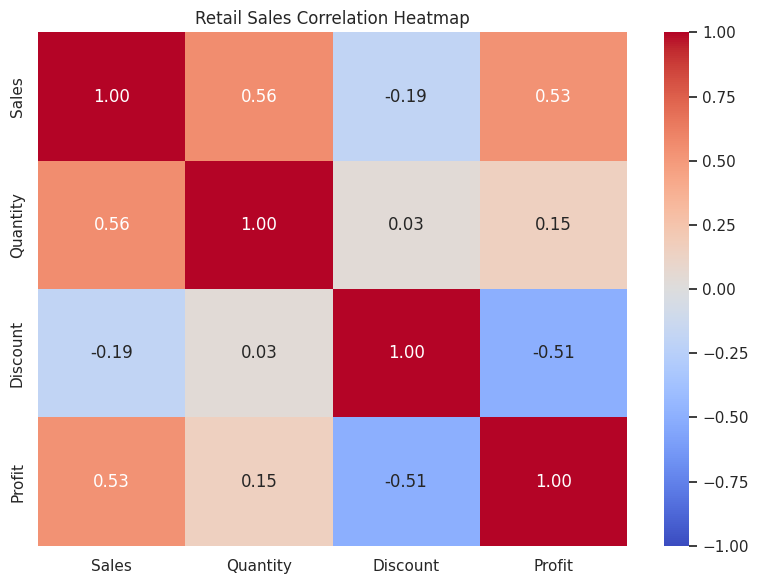

Correlation matrix:


,Sales,Quantity,Discount,Profit
Sales,1.000,0.556,-0.188,0.534
Quantity,0.556,1.000,0.034,0.154
Discount,-0.188,0.034,1.000,-0.505
Profit,0.534,0.154,-0.505,1.000


In [9]:
numeric_cols = ["Sales", "Quantity", "Discount", "Profit"]
correlation = df[numeric_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f",vmin=-1,vmax=1)
plt.title("Retail Sales Correlation Heatmap")
plt.tight_layout()
plt.show()
print("Correlation matrix:")
display(correlation.round(3))

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
categorical_features = ["Category","Sub-Category","Region","Segment","Ship Mode"]

numerical_features = ["Quantity", "Discount"]
model_df = df[categorical_features + numerical_features + ["Sales"]].dropna().copy()
X = model_df[categorical_features + numerical_features]
y = model_df["Sales"]
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20,random_state=42)
preprocessor = ColumnTransformer(transformers=[("categories",OneHotEncoder(handle_unknown="ignore"),categorical_features),("numbers", "passthrough", numerical_features)])
model = Pipeline([("preprocessor", preprocessor),("regressor", RandomForestRegressor(n_estimators=100,random_state=42,min_samples_leaf=2,n_jobs=-1))])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Sales prediction model trained successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Sales prediction model trained successfully!
Training records: 800
Testing records: 200


In [11]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R²): {r2:.3f}")
comparison = pd.DataFrame({"Actual Sales": y_test.values,"Predicted Sales": y_pred})
display(comparison.head(10).round(2))

Mean Absolute Error (MAE): 459.83
Root Mean Squared Error (RMSE): 742.46
R-squared (R²): 0.565


,Actual Sales,Predicted Sales
0,1519.92,1543.73
1,1885.32,1637.50
2,88.75,51.74
3,943.87,2482.22
4,976.08,947.41
5,3271.20,2664.63
6,50.12,1477.97
7,1607.76,1781.95
8,15.48,49.66
9,2455.88,2638.20


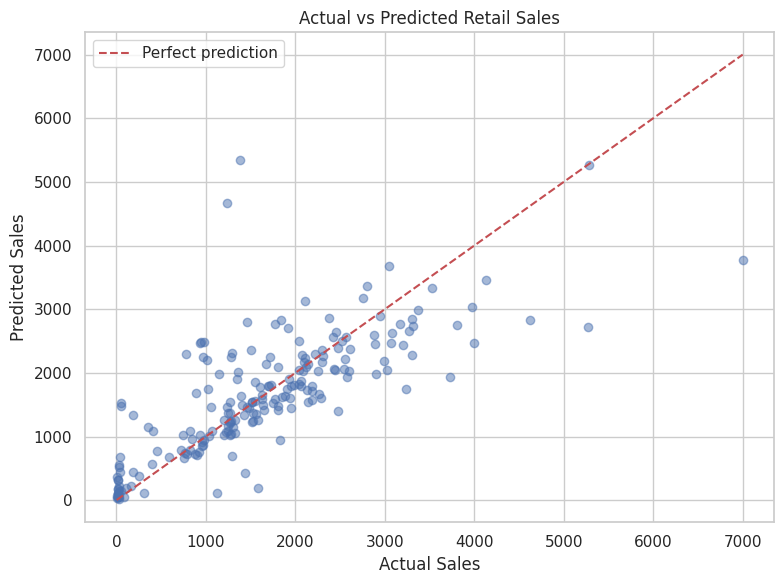

In [12]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val],[min_val, max_val],"r--",label="Perfect prediction")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Retail Sales")
plt.legend()
plt.tight_layout()
plt.show()

,Importance
Quantity,374.5668
Sub-Category,195.1002
Category,123.4766
Region,82.9031
Discount,53.0875
Ship Mode,33.0561
Segment,-11.0514


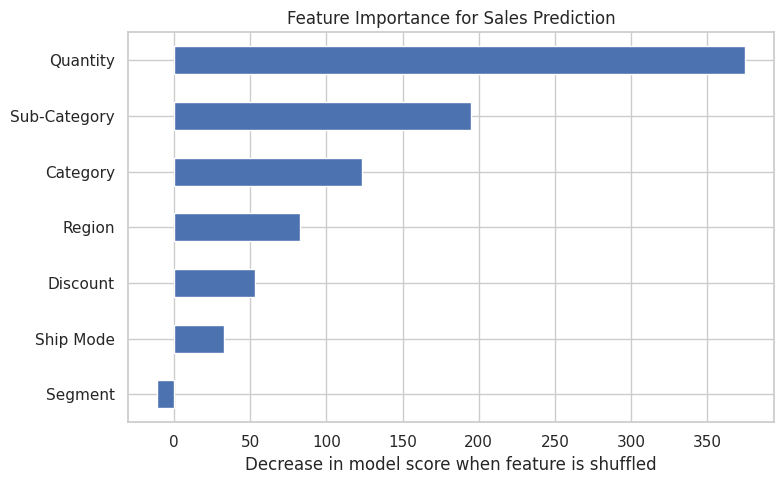

In [13]:
from sklearn.inspection import permutation_importance
importance_result = permutation_importance(model,X_test,y_test,n_repeats=3,random_state=42,scoring="neg_mean_absolute_error",n_jobs=-1)
importance = pd.Series(importance_result.importances_mean,index=X_test.columns).sort_values(ascending=False)
display(importance.to_frame("Importance").round(4))
importance.sort_values().plot(kind="barh",figsize=(8, 5),title="Feature Importance for Sales Prediction",xlabel="Decrease in model score when feature is shuffled")
plt.tight_layout()
plt.show()

In [14]:
category_summary.to_csv("retail_category_summary.csv")
monthly_sales.to_csv("retail_monthly_sales.csv", header=["Sales"])
product_summary.to_csv("retail_product_summary.csv")
comparison.to_csv("retail_sales_predictions.csv", index=False)
importance.to_csv("retail_feature_importance.csv", header=["Importance"])
metrics = pd.DataFrame({"Metric": ["MAE", "RMSE", "R2"],"Value": [mae, rmse, r2]})
metrics.to_csv("retail_model_metrics.csv", index=False)
print("Project outputs saved successfully!")
print("""
Files created:
1. retail_category_summary.csv
2. retail_monthly_sales.csv
3. retail_product_summary.csv
4. retail_sales_predictions.csv
5. retail_feature_importance.csv
6. retail_model_metrics.csv
""")


Project outputs saved successfully!

Files created:
1. retail_category_summary.csv
2. retail_monthly_sales.csv
3. retail_product_summary.csv
4. retail_sales_predictions.csv
5. retail_feature_importance.csv
6. retail_model_metrics.csv

